# Воронка приложения и A/A/B-тест шрифтов

## Содержание

- [Описание проекта](#section-1)
- [Загрузка данных и подготовка их к анализу](#section-2)
- [Предобрабокта данных](#section-3)
- [Изучение и проверка данных](#section-4)
- [Изучение воронки событий](#section-5)
- [Изучение результатов эксперимента](#section-6)

<a id="section-1"></a>

## Описание проекта

Мы работаем аналитиками в стартапе, который продаёт продукты питания, с незатейливым названием "Шестерочка". Нужно разобраться, **как ведут себя пользователи вашего мобильного приложения.**

По ходу проекта необходимо:
- Изучить воронку продаж: необходимо узнать, как пользователи доходят до покупки; сколько пользователей доходит до покупки, а сколько — «застревает» на предыдущих шагах? На каких именно?
- Провести и исследовать результаты A/A/B-эксперимента. Дизайнеры захотели поменять шрифты во всём приложении, а менеджеры испугались, что пользователям будет непривычно. Договорились принять решение по результатам A/A/B-теста. Пользователей разбили на 3 группы: 2 контрольные со старыми шрифтами и одну экспериментальную — с новыми. Необходимо выяснить, какой шрифт лучше.

<a id="section-2"></a>

## Загрузка данных и подготовка их к анализу

На данном этапе необходимо выполнить следующие действия:
* Импортировать библиотеки для анализа и визуализации данных;
* Прочитать датасет и сохранить его в соответствующую переменную;
* Изучить общую информацию о наборе данных;
* Вывести на экран наполнение таблицы данных;
* Сделать выводы о проделанных и будущих шагах;

In [1]:
# импортирование библиотек, необходимые для анализа и визуализации данных
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as st
import math

In [2]:
# прочитываем датасет и записываем его в соответствующую переменную
data = pd.read_csv('../data/raw/logs_exp.csv', sep='\t')
# выведем общую информацию о датасете
print('Общая информация о датасете')
data.info()
print()
# выведем первые 5 строк датасета
print('Первые 5 строк датасета "data"')
data.head()

Общая информация о датасете
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244126 entries, 0 to 244125
Data columns (total 4 columns):
 #   Column          Non-Null Count   Dtype 
---  ------          --------------   ----- 
 0   EventName       244126 non-null  object
 1   DeviceIDHash    244126 non-null  int64 
 2   EventTimestamp  244126 non-null  int64 
 3   ExpId           244126 non-null  int64 
dtypes: int64(3), object(1)
memory usage: 7.5+ MB

Первые 5 строк датасета "data"


,EventName,DeviceIDHash,EventTimestamp,ExpId
0,MainScreenAppear,4575588528974610257,1564029816,246
1,MainScreenAppear,7416695313311560658,1564053102,246
2,PaymentScreenSuccessful,3518123091307005509,1564054127,248
3,CartScreenAppear,3518123091307005509,1564054127,248
4,PaymentScreenSuccessful,6217807653094995999,1564055322,248


**Вывод**:
* Импортировали библиотеки для анализа и визуализации данных;
* Прочли датасет и сохранили в соответствующую переменную. Разбили значения на несколько столбцов, указав в качестве разделителя знак табуляции;
* Изучили общую информацию о наборе данных: **пропуски в значениях отсутствуют**;
* Вывели на экран первые 5 строк таблицы данных;
* Действия предобработки данных будут выполнены на следующем этапе;

<a id="section-3"></a>

## Предобрабокта данных

На данном этапе необходимо выполнить следующие действия:
* Изучить датасет на наличие дубликатов;
* Изучить датасет на предмет пересекающихся пользователей;
* Изменить названия полей таблицы - привести к "змеиному регистру";
* Изменить тип данных столбца с датой и временем события;
* Добавить отдельный столбец с датой;
* Сделать выводы о проделанных и будущих шагах;

In [3]:
# изучим датасет на наличие дубликатов
data.duplicated().sum()

413

In [4]:
# удалим дубликаты из датасета и перезапишем его
data = data.drop_duplicates().reset_index(drop=True)
# проверим выполнение команд
data.duplicated().sum()

0

Далее необходимо установить количество (если они присутствуют) пересекающихся пользователей: пользователи не должны одновременно находится в нескольких группах одновременно, чтобы не искажать результаты тестирования. Сделаем срезы по группам, объединим данные в один объект Series и подсчитаем количество пересекающихся пользователей.

In [5]:
# установим уникальные группы в датасете
print('Номера уникальных групп в исследовании:', data['ExpId'].unique())
# выполним срезы по датасету для каждой группы
group_246 = data[data['ExpId'] == 246]['DeviceIDHash']
group_247 = data[data['ExpId'] == 247]['DeviceIDHash']
group_248 = data[data['ExpId'] == 248]['DeviceIDHash']
# объединим данные в объект Series
groupped_246_247 = pd.Series(np.intersect1d(group_246, group_247))
groupped_247_248 = pd.Series(np.intersect1d(group_247, group_248))
groupped_246_248 = pd.Series(np.intersect1d(group_246, group_248))
# выведем на экран количество пересекающихся пользователей
print('Количество пересекающихся пользователей в группах 246 и 247:', len(groupped_246_247))
print('Количество пересекающихся пользователей в группах 247 и 248:', len(groupped_247_248))
print('Количество пересекающихся пользователей в группах 246 и 248:', len(groupped_246_248))

Номера уникальных групп в исследовании: [246 248 247]
Количество пересекающихся пользователей в группах 246 и 247: 0
Количество пересекающихся пользователей в группах 247 и 248: 0
Количество пересекающихся пользователей в группах 246 и 248: 0


In [6]:
# изменим названия полей датасета
data.columns = ['event_name','device_id_hash', 'event_timestamp','group_id']

In [7]:
# преобразуем поле с временем
data['event_timestamp'] = pd.to_datetime(data['event_timestamp'],unit='s')
# проверим выполнение команд
data.head()

,event_name,device_id_hash,event_timestamp,group_id
0,MainScreenAppear,4575588528974610257,2019-07-25 04:43:36,246
1,MainScreenAppear,7416695313311560658,2019-07-25 11:11:42,246
2,PaymentScreenSuccessful,3518123091307005509,2019-07-25 11:28:47,248
3,CartScreenAppear,3518123091307005509,2019-07-25 11:28:47,248
4,PaymentScreenSuccessful,6217807653094995999,2019-07-25 11:48:42,248


In [8]:
# добавим в датасет отдельный столбец с датой события
data['date'] = data['event_timestamp'].dt.date
# проверим выполнение команд
data.head()

,event_name,device_id_hash,event_timestamp,group_id,date
0,MainScreenAppear,4575588528974610257,2019-07-25 04:43:36,246,2019-07-25
1,MainScreenAppear,7416695313311560658,2019-07-25 11:11:42,246,2019-07-25
2,PaymentScreenSuccessful,3518123091307005509,2019-07-25 11:28:47,248,2019-07-25
3,CartScreenAppear,3518123091307005509,2019-07-25 11:28:47,248,2019-07-25
4,PaymentScreenSuccessful,6217807653094995999,2019-07-25 11:48:42,248,2019-07-25


In [9]:
# изменим тип данных столбца с id пользователя
data['device_id_hash'] = data['device_id_hash'].astype('str')

In [10]:
# выведем информацию о конечном датасете
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 243713 entries, 0 to 243712
Data columns (total 5 columns):
 #   Column           Non-Null Count   Dtype         
---  ------           --------------   -----         
 0   event_name       243713 non-null  object        
 1   device_id_hash   243713 non-null  object        
 2   event_timestamp  243713 non-null  datetime64[ns]
 3   group_id         243713 non-null  int64         
 4   date             243713 non-null  object        
dtypes: datetime64[ns](1), int64(1), object(3)
memory usage: 9.3+ MB


**Вывод**:
* Изучили датасет на наличие дубликатов: **Обнаружили явные дубликаты - удалили их**;
* Изучили датасет на предмет пересекающихся пользователей: **Пересекающихся пользователей не найдено**;
* Изменили названия полей таблицы - привели их к "змеиному регистру";
* Изменили тип данных столбца с датой и временем события - **привели к datetime**;
* Добавили отдельный столбец с датой;

<a id="section-4"></a>

## Изучение и проверка данных

На данном этапе необходимо выполнить следующие действия:
* Установить количество событий в логе;
* Установить количество посетителей в логе;
* Установить среднее количество событий на одного пользователя;
* Найти максимальную и минимальную дату лога - установить период;
* Построить гистограмму по дате и времени;
* Определить и исключить из исследования старые данные;
* Выполнить проверку наличия данных по всем трем группам для исследования;
* Сделать выводы о проделанных и будущих шагах;

In [11]:
# установим количество событий в логе
print('Cуммарное количество событий:', data['event_name'].count())
print('Количество каждого отдельного события:')
data['event_name'].value_counts()

Cуммарное количество событий: 243713
Количество каждого отдельного события:


MainScreenAppear           119101
OffersScreenAppear          46808
CartScreenAppear            42668
PaymentScreenSuccessful     34118
Tutorial                     1018
Name: event_name, dtype: int64

* Появление Главного экрана - 119 101;
* Появление экрана предложений - 46 808;
* Появление экрана корзины - 42 668;
* Появление экрана успешной оплаты - 34 118;
* Руководство - 1 018;

In [12]:
# установим количество посетителей в логе
print('Количество уникальных посетителей в логе:', len(data['device_id_hash'].unique()))

Количество уникальных посетителей в логе: 7551


In [13]:
# найдем среднее количество событий на одного пользователя
avg_events = data['event_name'].count() / len(data['device_id_hash'].unique())
# выведем среднее значение на экран
print('Среднее количество событий на одного пользователя:', math.floor(avg_events))

Среднее количество событий на одного пользователя: 32


In [14]:
# установим минимальную дату в логе
min_date = min(data['date'])
print('Минимальная дата события:', min_date)
# установим максимальную дату в логе
max_date = max(data['date'])
print('Максимальная дата события:', max_date)

Минимальная дата события: 2019-07-25
Максимальная дата события: 2019-08-07


Установлено, что мы располагаем данными с 25 июля 2019 года по 07 августа 2019 года - двухнедельный временной промежуток.

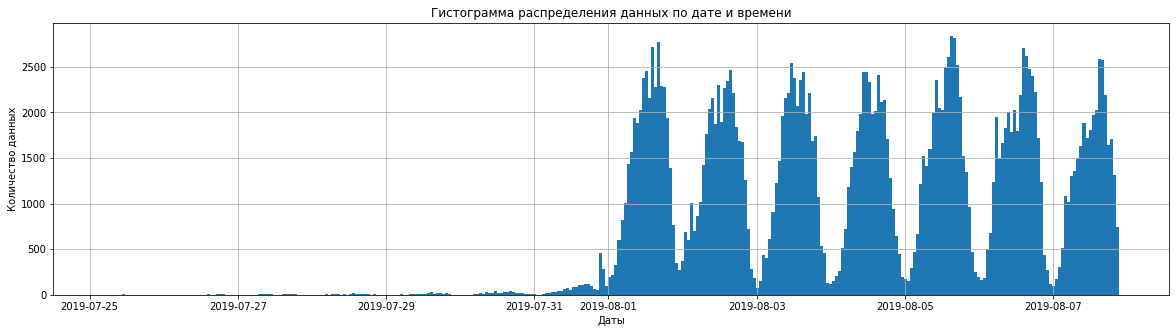

In [15]:
# построим гистограмму распределения по дате и времени
data['event_timestamp'].hist(figsize=(20, 5), bins=14*24)
plt.title('Гистограмма распределения данных по дате и времени')
plt.xlabel('Даты')
plt.ylabel('Количество данных')
plt.show()

Увеличили размер гистограммы, чтобы увидеть распределение данных. Заметно, как увеличивается взаимодействие пользователей с платформой с 1 августа 2019 года. Какой-то триггер побудил интерес пользователей к платформе и заставил их больше взаимодействовать: мы не можем точно утверждать, проходили ли они весь путь от просмотра главной страницы до совершения покупки, но взаимодействие увеличилось в разы.

In [16]:
# создадим переменную с отображением даты для фильтрации
filter_date = pd.to_datetime("2019-08-01").date()
# изучим количество взаимодействий с платформой до 01 августа 2019 года
print(len(data[data['date'] < filter_date]['event_name']))
# изучим количество взаимодействий с платформой после 01 августа 2019 года
print(len(data[data['date'] >= filter_date]['event_name']))

2826
240887


Еще раз убедились, что подавляющее большинство взаимодействий с платформой было в период 01 по 07 августа 2019 года (с учетом "доезжающих" действий). Отбросим значения до первого августа и запишем оставшиеся данные в новую переменную:

In [17]:
data_new = data[data['date'] >= filter_date]

In [18]:
# проверим, что датасет содержит данные для всех трех исследуемых групп
data['group_id'].value_counts()

248    85582
246    80181
247    77950
Name: group_id, dtype: int64

Отлично, у нас есть данные по всем трем исследуемым группам - можно делать выводы по выполненным шагам и переходить к следующему этапу исследования.

**Вывод**:
* Установили количество событий в логе (**Суммарно - 243 713**):
    * Появление Главного экрана - 119 101;
    * Появление экрана предложений - 46 808;
    * Появление экрана корзины - 42 668;
    * Появление экрана успешной оплаты - 34 118;
    * Руководство - 1 018;
* Установили количество пользователей в логе - **7 551 человек**;
* Установили среднее количество действий на одного пользователя - **32**;
* Нашли максимальную и минимальную дату лога и установили период лога - **25 июля 2019 года по 07 августа 2019 года**;
* Построили гистограмму распределения по дате и времени;
* Определили и исключили из исследования старые данные - **до 01 августа 2019 года**;
* Процент потерь пользователей после чистки данных составил: **-0.23%** (произошло снижение с 7 551 пользователя до 7 534 пользователей);
* Процент потерь событий на 1 пользователя после чистки данных составил: **-0.0000001%** (произошло снижение с 32 событий до 31 события);
* Выполнили проверку и установили наличие данных по всем трем группам для исследования;

In [19]:
# посмотрим сколько пользователей мы потеряли при чистке данных
print('БЕЗ ЧИСТКИ: Всего пользователей в логе %d.' % (data['device_id_hash'].nunique()))
print('ПОСЛЕ ЧИСТКИ: Всего пользователей в логе %d.' % (data_new['device_id_hash'].nunique()))
print('Процент потери пользователей:{:.2%}'.format(((data_new['device_id_hash'].nunique() - data['device_id_hash'].nunique()))/data['device_id_hash'].nunique()))

БЕЗ ЧИСТКИ: Всего пользователей в логе 7551.
ПОСЛЕ ЧИСТКИ: Всего пользователей в логе 7534.
Процент потери пользователей:-0.23%


In [20]:
# взглянем на процент потери событий на одного пользователя
print('БЕЗ ЧИСТКИ: В среднем событий на пользователя %d.' % (data['event_name'].count() / len(data['device_id_hash'].unique())))
print('ПОСЛЕ ЧИСТКИ: В среднем событий на пользователя %d.' % (data_new['event_name'].count() / len(data_new['device_id_hash'].unique())))
# потеря составила 1 событие на пользователя, поэтому, чтобы не громоздить код, поделим единицу на количество 
print('Процент потери событий на одного пользователя:{:.7%}'.format(-1/data['event_name'].count() / len(data['device_id_hash'].unique())))

БЕЗ ЧИСТКИ: В среднем событий на пользователя 32.
ПОСЛЕ ЧИСТКИ: В среднем событий на пользователя 31.
Процент потери событий на одного пользователя:-0.0000001%


<a id="section-5"></a>

## Изучение воронки событий

На данном этапе необходимо выполнить следующие действия:
* Изучить события в логе: найти их частоту и отсортировать по частоте;
* Найти количество того, сколько раз пользователи совершали то или иное событие. Отсортировать события по числу пользователей. Посчитать долю пользователей, которые хоть раз совершали событие;
* Сделать предположение, в каком порядке происходят события (вывод не нужно учитывать при расчете воронки);
* Построить воронку;
* Определить, на каком шаге теряются больше всего пользователей;
* Определить, какая доля пользователей доходит до первого события оплаты;

In [21]:
# определим количеством событий в логе и отсортируем их по частоте
data_new['event_name'].value_counts()

MainScreenAppear           117328
OffersScreenAppear          46333
CartScreenAppear            42303
PaymentScreenSuccessful     33918
Tutorial                     1005
Name: event_name, dtype: int64

Как видно, изучать руководство пользования приложением никто не хочет - пользователи пропускают этот скучный шаг и сразу приступают к знакомству с интерфейсом и возможностями приложения. Изучение конверсии пользователей предстоит в последующих действиях, но уже сейчас можно сказать, что **до экрана с предложениями товаров доходит около половины пользователей, открывших страницу главного экрана.**

In [22]:
# определим количество пользователей, которые совершали то или иное событие
users_pivot = (data_new.pivot_table(index='event_name', values='device_id_hash', aggfunc='nunique')
               .sort_values(by='device_id_hash', ascending=False))
users_pivot

,device_id_hash
event_name,
MainScreenAppear,7419
OffersScreenAppear,4593
CartScreenAppear,3734
PaymentScreenSuccessful,3539
Tutorial,840


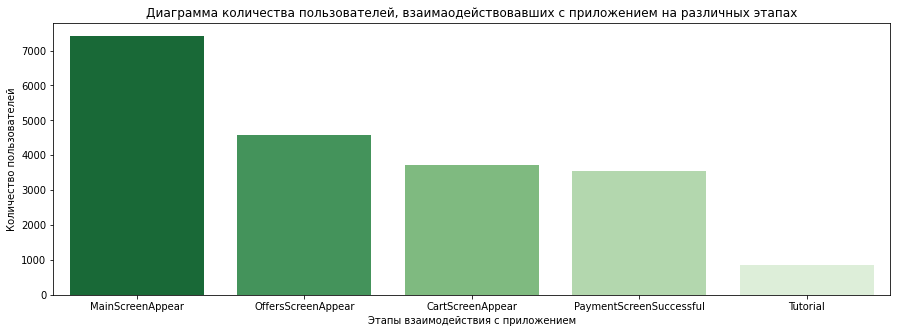

In [23]:
# построим столбчатую диаграмму для визуализации данных
plt.figure(figsize=(15,5))
sns.barplot(x=users_pivot.index, y='device_id_hash', data=users_pivot, palette='Greens_r')
plt.title('Диаграмма количества пользователей, взаимаодействовавших с приложением на различных этапах')
plt.xlabel('Этапы взаимодействия с приложением')
plt.ylabel('Количество пользователей')
plt.show()

Как и в проверке по количеству совершенных действий на каждом этапе, большая часть пользователей прошла главный экран, после чего до экрана с предложением товаров дошли не все. Заметно так же, что около 200 человек передумали совершать покупку в самый последний момент - интересно, что может быть причиной: нехватка средств на карте, не прошла транзакция или личные мотивы?

In [24]:
# запишем количество уникальных пользователей в отдельную переменную
total_users = len(data_new['device_id_hash'].unique())
# определим, сколько пользователей совершило хотя бы одно действие
total_events_byusers = data_new.pivot_table(index='device_id_hash', values='event_name', aggfunc='count')
total_events_byusers = len(total_events_byusers[total_events_byusers['event_name'] == 1])
# найдем процент пользователей, совершивших хоть раз событие
print('Количество пользователей совершивших событие хоть один раз: {:.2%}'.format(total_events_byusers / total_users))

Количество пользователей совершивших событие хоть один раз: 1.58%


In [42]:
# рассмотрим, какова доля пользователей, которые хоть раз совершали событие
# для этого шага запишем в отдельную переменную общее количество пользователей
total_users_new = data_new['device_id_hash'].nunique()
users_pivot['share'] = round(users_pivot['device_id_hash'] / total_users_new * 100, 1)
users_pivot

,device_id_hash,share
event_name,,
MainScreenAppear,7419,98.5
OffersScreenAppear,4593,61.0
CartScreenAppear,3734,49.6
PaymentScreenSuccessful,3539,47.0
Tutorial,840,11.1


Исходя из приведенных этапов очередность выполнения действий должна быть следующая:
* Изучение руководства пользователя (шаг **Tutorial**);
* Просмотр главного экрана приложения (шаг **MainScreenAppear**);
* Просмотр окна с предложениями товаров (шаг **OffersScreenAppear**);
* Переход на окно оформления заказа (шаг **CartScreenAppear**);
* Оплата заказа (шаг **PaymentScreenSuccessful**);

На деле же большая часть опльзователей минует шаг изучения руководства и приступает к практическому взаимодействию с интерфейсом приложения. Поэтому "на деле" для большинства характерна следующая последовательность действий, минуя изучение руководства:
* Просмотр главного экрана приложения (шаг **MainScreenAppear**);
* Просмотр окна с предложениями товаров (шаг **OffersScreenAppear**);
* Переход на окно оформления заказа (шаг **CartScreenAppear**);
* Оплата заказа (шаг **PaymentScreenSuccessful**);

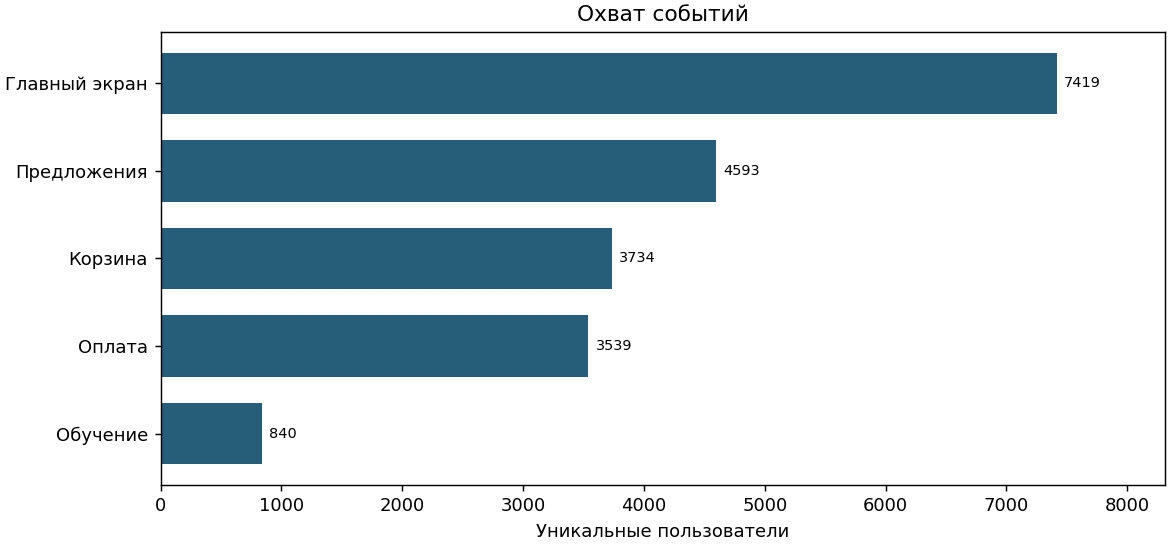

In [43]:
# построим воронку пользователей - для этого построим интерактивный график воронки с помощью библиотеки plotly
from plotly import graph_objects as go
fig = go.Figure()
fig = go.Figure(go.Funnel(
    y = users_pivot.index,
    x = users_pivot['device_id_hash']))
fig.update_layout(title='Воронка пользователей продуктового мобильного приложения', title_x = 0.5)
fig.show()

На основании построенного интерактивного графика можно сделать следующие выводы:
1. Определили на каком этапе отсеивается больше всего пользователей - если исключить этап изучения руководства пользователя, то **больше всего пользователей отсеивается на втором этапе - OffersScreenAppear (ушло 38,1% от числа пользователей взаимодействовавших с главным экраном)**;
2. До первого события оплаты доходит 47,7% пользователей от того количества, которое было на первом этапе;
3. Как правило пользователи, дошедшие до этапа оплаты покупки, успешно ее завершают. Исключение составляют только 5.2% от числа пользователей, начавших оформлять и оплачивать покупку, которые не дошли до успешной оплаты;

**Вывод**:
* Изучили события в логе: нашли их частоту и отсортировать по частоте:
    * MainScreenAppear - 117328
    * OffersScreenAppear - 46333
    * CartScreenAppear - 42303
    * PaymentScreenSuccessful - 33918
    * Tutorial - 1005;
* Нашли количество того, сколько раз пользователи совершали то или иное событие. Отсортировали события по числу пользователей. Посчитали долю пользователей, которые хоть раз совершали событие:
    * MainScreenAppear - 7419
    * OffersScreenAppear - 4593
    * CartScreenAppear - 3734
    * PaymentScreenSuccessful - 3539
    * Tutorial - 840

* Сделали предположение, в каком порядке происходят события;
* Построили воронку пользователей;
* Определили на каком этапе отсеивается больше всего пользователей - если исключить этап изучения руководства пользователя, то больше всего пользователей отсеивается на втором этапе - OffersScreenAppear (снижение охвата на 38,1% от числа пользователей взаимодействовавших с главным экраном);
* До первого события оплаты доходит 47.7% пользователей от того количества, которое было на первом этапе;

<a id="section-6"></a>

## Изучение результатов эксперимента

На данном этапе необходимо выполнить следующие действия:
* Установить количество пользователей в каждой группе;
* Проверить, находят ли статистические критерии разницу между выборками 246 и 247;
* Выбрать самое популярное событие. Посчитать число пользователей, совершивших это событие в каждой из контрольных групп. Посчитать долю пользователей, совершивших это событие. Проверить, будет ли отличие между группами статистически достоверным. Проделать то же самое для всех других событий;
* Аналогично поступить с группой с изменённым шрифтом. Сравнить результаты с каждой из контрольных групп в отдельности по каждому событию. Сравнить результаты с объединённой контрольной группой;
* Сделать выводы о проделанных действиях;

In [27]:
# изучим количество пользователей в каждой экспериментальной группе
users_quantity = data_new.groupby('group_id')['device_id_hash'].nunique()
users_quantity

group_id
246    2484
247    2513
248    2537
Name: device_id_hash, dtype: int64

Проверим, находят ли статистические критерии разницу между выборками 246 и 247.

**Сформируем критерии успешного А/А-тестирования**:
* Количество пользователей в различных группах различается не более, чем на 1% или 0.5%;
* Для всех групп фиксируют и отправляют в системы аналитики данные об одном и том же;
* Различие ключевых метрик по группам не превышает 1% и не имеет статистической значимости;
* Попавший в одну из групп посетитель остаётся в этой группе до конца теста. Если пользователь видит разные версии исследуемой страницы в ходе одного исследования, неизвестно, какая именно повлияла на его решения. Значит, и результаты такого теста нельзя интерпретировать однозначно;

In [28]:
# перезапишем ранее созданные переменные, где выделяли данные для отдельных групп тестирования:
# 'group_246', 'group_247', 'group_248' и отсечем этап изучения руководства пользователей
group_246 = data_new[(data_new['group_id'] == 246) & (data_new['event_name'] != 'Tutorial')]
group_247 = data_new[(data_new['group_id'] == 247) & (data_new['event_name'] != 'Tutorial')]
group_248 = data_new[(data_new['group_id'] == 248) & (data_new['event_name'] != 'Tutorial')]

In [29]:
# сформируем пользовательские воронки
funnel_246 = group_246.groupby('event_name')['device_id_hash'].nunique().sort_values(ascending=False).to_frame().reset_index()\
        .rename(columns={'device_id_hash': 'total_users'})
funnel_247 = group_247.groupby('event_name')['device_id_hash'].nunique().sort_values(ascending=False).to_frame().reset_index()\
        .rename(columns={'device_id_hash': 'total_users'})
funnel_248 = group_248.groupby('event_name')['device_id_hash'].nunique().sort_values(ascending=False).to_frame().reset_index()\
        .rename(columns={'device_id_hash': 'total_users'})

In [30]:
# сколько пользователей находится в 247 группе относительно 246-ой группы
funnel_247['total_users'].sum() / funnel_246['total_users'].sum() * 100

98.97801176834933

In [31]:
# изучим как разнятся данные в 247-ой группе относительно 246-ой группы
funnel_247['total_users'] / funnel_246['total_users'] * 100

0    101.061224
1     98.573281
2     97.788310
3     96.500000
Name: total_users, dtype: float64

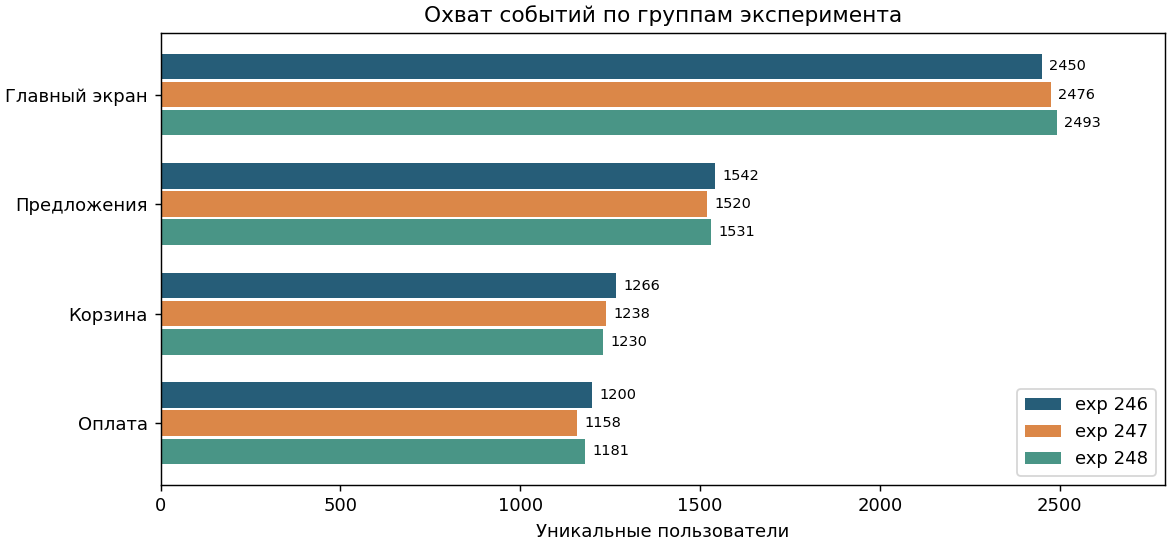

In [32]:
# построим пользовательскую воронку по 3-ем исследуемым группам - изучим как отсеиваются пользователи
# на разных этапах
fig = go.Figure()

fig.add_trace(go.Funnel(
    name = 'exp 246',
    y = funnel_246['event_name'],
    x = funnel_246['total_users'],
    ))

fig.add_trace(go.Funnel(
    name = 'exp 247',
    y = funnel_247['event_name'],
    x = funnel_247['total_users'],
    ))

fig.add_trace(go.Funnel(
    name = 'exp 248',
    y = funnel_248['event_name'],
    x = funnel_248['total_users'],
    ))

fig.show()

**Вывод**:
Критерии не идеальны, но приемлимые - разницы между группами нет.

Посмотрим статистику по самому популярному событию - просмотру главного экрана.

In [33]:
# построим сводную таблицу по трем исследуемым группам, где отобразим пользовательскую воронку
all_funnels = data_new.pivot_table(index='event_name', columns='group_id',values='device_id_hash',aggfunc='nunique')\
                       .sort_values(246,ascending=False)
# добавим столбец с суммарным количеством пользователей из 246 и 247 групп
all_funnels['246+247'] = all_funnels[246] + all_funnels[247]
all_funnels.drop(['Tutorial'], inplace=True)
all_funnels

group_id,246,247,248,246+247
event_name,,,,
MainScreenAppear,2450,2476,2493,4926
OffersScreenAppear,1542,1520,1531,3062
CartScreenAppear,1266,1238,1230,2504
PaymentScreenSuccessful,1200,1158,1181,2358


Количество пользователей, совершивших событие "Просмотр главного экрана":
* Группа 246 - 2 450 пользователей;
* Группа 247 - 2 476 пользователей;
* Группа 248 - 2 493 пользователей;

In [48]:
users = users_quantity.to_frame().reset_index()
users.loc[3] = ['246+247', users_quantity.loc[246] + users_quantity.loc[247]]

In [49]:
users = users.set_index(users.columns[0])
users

,device_id_hash
group_id,
246,2484
247,2513
248,2537
246+247,4997


In [36]:
# Воспользуемся Z-критерием
def z_test(exp1, exp2, event, alpha): 
    p1_ev = all_funnels.loc[event, exp1]
    p2_ev = all_funnels.loc[event, exp2] 
    p1_us = users.loc[exp1, 'device_id_hash'] 
    p2_us = users.loc[exp2, 'device_id_hash'] 
    p1 = p1_ev / p1_us 
    p2 = p2_ev / p2_us 
    difference = p1 - p2
    p_combined = (p1_ev + p2_ev) / (p1_us + p2_us) 
    z_value = difference / math.sqrt(p_combined * (1 - p_combined) * (1 / p1_us + 1 / p2_us))
    distr = st.norm(0, 1)
    p_value = (1 - distr.cdf(abs(z_value))) * 2
    print('Проверка для  {} и {}, событие: {}, p-значение: {p_value:.2f}'.format(exp1, exp2, event, p_value=p_value))
    if (p_value < alpha):
        print("Отвергаем нулевую гипотезу")
    else:
        print("Не получилось отвергнуть нулевую гипотезу")

**Сформулируем гипотезы**

* Н0 - различия между экспериментальными группами, совершившими указанное событие, статистически не значимы

* Н1 - различия между экспериментальными группами, совершившими указанное событие, статистически значимы

Пороговое значение alpha примем за 5%.

In [37]:
for event in all_funnels.index:
    z_test(246, 247, event, 0.05)
    print()

Проверка для  246 и 247, событие: MainScreenAppear, p-значение: 0.76
Не получилось отвергнуть нулевую гипотезу

Проверка для  246 и 247, событие: OffersScreenAppear, p-значение: 0.25
Не получилось отвергнуть нулевую гипотезу

Проверка для  246 и 247, событие: CartScreenAppear, p-значение: 0.23
Не получилось отвергнуть нулевую гипотезу

Проверка для  246 и 247, событие: PaymentScreenSuccessful, p-значение: 0.11
Не получилось отвергнуть нулевую гипотезу



**Вывод**:
Вывод о различии долей сделать нельзя

In [38]:
# проделаем ту же проверку для группы с измененным шрифтом
for event in all_funnels.index:
    z_test(246, 248, event, 0.05)
    print()

Проверка для  246 и 248, событие: MainScreenAppear, p-значение: 0.29
Не получилось отвергнуть нулевую гипотезу

Проверка для  246 и 248, событие: OffersScreenAppear, p-значение: 0.21
Не получилось отвергнуть нулевую гипотезу

Проверка для  246 и 248, событие: CartScreenAppear, p-значение: 0.08
Не получилось отвергнуть нулевую гипотезу

Проверка для  246 и 248, событие: PaymentScreenSuccessful, p-значение: 0.21
Не получилось отвергнуть нулевую гипотезу



In [39]:
for event in all_funnels.index:
    z_test(247, 248, event, 0.05)
    print()

Проверка для  247 и 248, событие: MainScreenAppear, p-значение: 0.46
Не получилось отвергнуть нулевую гипотезу

Проверка для  247 и 248, событие: OffersScreenAppear, p-значение: 0.92
Не получилось отвергнуть нулевую гипотезу

Проверка для  247 и 248, событие: CartScreenAppear, p-значение: 0.58
Не получилось отвергнуть нулевую гипотезу

Проверка для  247 и 248, событие: PaymentScreenSuccessful, p-значение: 0.74
Не получилось отвергнуть нулевую гипотезу



In [40]:
for event in all_funnels.index:
    z_test('246+247', 248, event, 0.05)
    print()

Проверка для  246+247 и 248, событие: MainScreenAppear, p-значение: 0.29
Не получилось отвергнуть нулевую гипотезу

Проверка для  246+247 и 248, событие: OffersScreenAppear, p-значение: 0.43
Не получилось отвергнуть нулевую гипотезу

Проверка для  246+247 и 248, событие: CartScreenAppear, p-значение: 0.18
Не получилось отвергнуть нулевую гипотезу

Проверка для  246+247 и 248, событие: PaymentScreenSuccessful, p-значение: 0.60
Не получилось отвергнуть нулевую гипотезу



**Вывод**:
Вывод о различии долей сделать нельзя.

**Вывод**:
* Установили количество пользователей в каждой группе:
    * Группа 246 - 2 484
    * Группа 247 - 2 513
    * Группа 248 - 2 537
* Проверили, находят ли статистические критерии разницу между выборками 246 и 247 - разницы между группами нет;
* Выбрали самое популярное событие - "Просмотр главного экрана". Посчитали число пользователей, совершивших это событие в каждой из контрольных групп. Проверили, будет ли отличие между группами статистически достоверным. Проделали то же самое для всех других событий - различий нет;
* Аналогично поступили с группой с изменённым шрифтом. Сравнили результаты с каждой из контрольных групп в отдельности по каждому событию. Сравнили результаты с объединённой контрольной группой;
* Проделали 4 А/А теста и 12 А/В тестов. Использовали критерий в 5%. На всех предыдущих этапах пользовательская воронка намекала, что различий нет.

**Резюме**

По рассмотренным событиям статистически значимого эффекта смены шрифта не обнаружено. Величина возможного эффекта и эквивалентность вариантов требуют отдельной оценки.